In [1]:
# %pip install --upgrade plotly

In [2]:
import pandas as pd
import numpy as np
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df_data = pd.read_csv("nobel_prize_data.csv")

In [4]:
df_data.shape

(962, 16)

In [5]:
df_data.head()

,year,category,prize,motivation,prize_share,laureate_type,full_name,birth_date,birth_city,birth_country,birth_country_current,sex,organization_name,organization_city,organization_country,ISO
0,1901,Chemistry,The Nobel Prize in Chemistry 1901,"""in recognition of the extraordinary services ...",1/1,Individual,Jacobus Henricus van 't Hoff,1852-08-30,Rotterdam,Netherlands,Netherlands,Male,Berlin University,Berlin,Germany,NLD
1,1901,Literature,The Nobel Prize in Literature 1901,"""in special recognition of his poetic composit...",1/1,Individual,Sully Prudhomme,1839-03-16,Paris,France,France,Male,NaN,NaN,NaN,FRA
2,1901,Medicine,The Nobel Prize in Physiology or Medicine 1901,"""for his work on serum therapy, especially its...",1/1,Individual,Emil Adolf von Behring,1854-03-15,Hansdorf (Lawice),Prussia (Poland),Poland,Male,Marburg University,Marburg,Germany,POL
3,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,Individual,Frédéric Passy,1822-05-20,Paris,France,France,Male,NaN,NaN,NaN,FRA
4,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,Individual,Jean Henry Dunant,1828-05-08,Geneva,Switzerland,Switzerland,Male,NaN,NaN,NaN,CHE


In [6]:
df_data.columns

Index(['year', 'category', 'prize', 'motivation', 'prize_share',
       'laureate_type', 'full_name', 'birth_date', 'birth_city',
       'birth_country', 'birth_country_current', 'sex', 'organization_name',
       'organization_city', 'organization_country', 'ISO'],
      dtype='object')

In [7]:
df_data.describe()

,year
count,962.000000
mean,1971.816008
std,33.813537
min,1901.000000
25%,1948.000000
50%,1977.000000
75%,2001.000000
max,2020.000000


In [8]:
df_data.duplicated().sum()

np.int64(0)

In [9]:
df_data.isna().sum()

,0
year,0
category,0
prize,0
motivation,88
prize_share,0
laureate_type,0
full_name,0
birth_date,28
birth_city,31
birth_country,28


In [10]:
# Converting birth_date from str to datetime
df_data.birth_date = pd.to_datetime(df_data.birth_date)
df_data.head()

,year,category,prize,motivation,prize_share,laureate_type,full_name,birth_date,birth_city,birth_country,birth_country_current,sex,organization_name,organization_city,organization_country,ISO
0,1901,Chemistry,The Nobel Prize in Chemistry 1901,"""in recognition of the extraordinary services ...",1/1,Individual,Jacobus Henricus van 't Hoff,1852-08-30,Rotterdam,Netherlands,Netherlands,Male,Berlin University,Berlin,Germany,NLD
1,1901,Literature,The Nobel Prize in Literature 1901,"""in special recognition of his poetic composit...",1/1,Individual,Sully Prudhomme,1839-03-16,Paris,France,France,Male,NaN,NaN,NaN,FRA
2,1901,Medicine,The Nobel Prize in Physiology or Medicine 1901,"""for his work on serum therapy, especially its...",1/1,Individual,Emil Adolf von Behring,1854-03-15,Hansdorf (Lawice),Prussia (Poland),Poland,Male,Marburg University,Marburg,Germany,POL
3,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,Individual,Frédéric Passy,1822-05-20,Paris,France,France,Male,NaN,NaN,NaN,FRA
4,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,Individual,Jean Henry Dunant,1828-05-08,Geneva,Switzerland,Switzerland,Male,NaN,NaN,NaN,CHE


In [11]:
col_subset = ['year','category', 'laureate_type',
              'birth_date','full_name', 'organization_name']
df_data.loc[df_data.birth_date.isna()][col_subset]


,year,category,laureate_type,birth_date,full_name,organization_name
24,1904,Peace,Organization,NaT,Institut de droit international (Institute of ...,NaN
60,1910,Peace,Organization,NaT,Bureau international permanent de la Paix (Per...,NaN
89,1917,Peace,Organization,NaT,Comité international de la Croix Rouge (Intern...,NaN
200,1938,Peace,Organization,NaT,Office international Nansen pour les Réfugiés ...,NaN
215,1944,Peace,Organization,NaT,Comité international de la Croix Rouge (Intern...,NaN
237,1947,Peace,Organization,NaT,American Friends Service Committee (The Quakers),NaN
238,1947,Peace,Organization,NaT,Friends Service Council (The Quakers),NaN
283,1954,Peace,Organization,NaT,Office of the United Nations High Commissioner...,NaN
348,1963,Peace,Organization,NaT,Comité international de la Croix Rouge (Intern...,NaN
349,1963,Peace,Organization,NaT,Ligue des Sociétés de la Croix-Rouge (League o...,NaN


In [12]:
# Converting the prize share column from str to float
seperated_values = df_data.prize_share.str.split('/', expand=True)
numerator = pd.to_numeric(seperated_values[0])
denominator = pd.to_numeric(seperated_values[1])
df_data['share_pct'] = numerator / denominator
df_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 962 entries, 0 to 961
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   year                   962 non-null    int64         
 1   category               962 non-null    object        
 2   prize                  962 non-null    object        
 3   motivation             874 non-null    object        
 4   prize_share            962 non-null    object        
 5   laureate_type          962 non-null    object        
 6   full_name              962 non-null    object        
 7   birth_date             934 non-null    datetime64[ns]
 8   birth_city             931 non-null    object        
 9   birth_country          934 non-null    object        
 10  birth_country_current  934 non-null    object        
 11  sex                    934 non-null    object        
 12  organization_name      707 non-null    object        
 13  organ

In [14]:
# Answering the question "What percent of the Nobel laureates are women?"
biology = df_data.sex.value_counts()

fig = px.pie(labels=biology.index,
             values=biology.values,
             title='Percentage of Male vs. Female Winners',
             names=biology.index,
             hole=0.4,
             )

fig.update_traces(textposition='inside', textfont_size=15,textinfo='percent')

fig.show()

In [15]:
# Who are the first 3 female Nobel laureates?
info_col = ['full_name', 'prize','motivation', 'birth_country', 'organization_name' ]
df_data.loc[df_data.sex == 'Female'][info_col].head(3)

,full_name,prize,motivation,birth_country,organization_name
18,"Marie Curie, née Sklodowska",The Nobel Prize in Physics 1903,"""in recognition of the extraordinary services ...",Russian Empire (Poland),NaN
29,"Baroness Bertha Sophie Felicita von Suttner, n...",The Nobel Peace Prize 1905,NaN,Austrian Empire (Czech Republic),NaN
51,Selma Ottilia Lovisa Lagerlöf,The Nobel Prize in Literature 1909,"""in appreciation of the lofty idealism, vivid ...",Sweden,NaN


In [16]:
# Did some people get a Nobel Prize more than once? If so, who were they?
num_winners = df_data['full_name'].duplicated().sum()
is_winner = df_data.duplicated(subset=['full_name'], keep=False)
multiple_winners = df_data[is_winner]
print(f'There are {multiple_winners.full_name.nunique()}' \
      ' winners who were awarded the prize more than once.')


col_subset = ['year', 'category', 'laureate_type', 'full_name']
multiple_winners[col_subset]

There are 6 winners who were awarded the prize more than once.


,year,category,laureate_type,full_name
18,1903,Physics,Individual,"Marie Curie, née Sklodowska"
62,1911,Chemistry,Individual,"Marie Curie, née Sklodowska"
89,1917,Peace,Organization,Comité international de la Croix Rouge (Intern...
215,1944,Peace,Organization,Comité international de la Croix Rouge (Intern...
278,1954,Chemistry,Individual,Linus Carl Pauling
283,1954,Peace,Organization,Office of the United Nations High Commissioner...
297,1956,Physics,Individual,John Bardeen
306,1958,Chemistry,Individual,Frederick Sanger
340,1962,Peace,Individual,Linus Carl Pauling
348,1963,Peace,Organization,Comité international de la Croix Rouge (Intern...


In [17]:
# In how many categories are prizes awarded?
num_categories = df_data['category'].nunique()
print(num_categories)

prizes_per_category = df_data.category.value_counts()
print(prizes_per_category)

6
category
Medicine      222
Physics       216
Chemistry     186
Peace         135
Literature    117
Economics      86
Name: count, dtype: int64


In [18]:
bar = px.bar(x=prizes_per_category.index,
             y=prizes_per_category.values,
             title='Number of Prizes Awarded per Category',
             hover_name=prizes_per_category.index,
             color=prizes_per_category.values,
             color_continuous_scale='Aggrnyl')

bar.update_layout(xaxis_title='Category',
                  yaxis_title='Number of prices',
                  coloraxis_showscale=False,)

bar.show()

In [19]:
df_data[df_data.category == 'Economics'].sort_values('year')


,year,category,prize,motivation,prize_share,laureate_type,full_name,birth_date,birth_city,birth_country,birth_country_current,sex,organization_name,organization_city,organization_country,ISO,share_pct
393,1969,Economics,The Sveriges Riksbank Prize in Economic Scienc...,"""for having developed and applied dynamic mode...",1/2,Individual,Jan Tinbergen,1903-04-12,the Hague,Netherlands,Netherlands,Male,The Netherlands School of Economics,Rotterdam,Netherlands,NLD,0.500000
394,1969,Economics,The Sveriges Riksbank Prize in Economic Scienc...,"""for having developed and applied dynamic mode...",1/2,Individual,Ragnar Frisch,1895-03-03,Oslo,Norway,Norway,Male,University of Oslo,Oslo,Norway,NOR,0.500000
402,1970,Economics,The Sveriges Riksbank Prize in Economic Scienc...,"""for the scientific work through which he has ...",1/1,Individual,Paul A. Samuelson,1915-05-15,"Gary, IN",United States of America,United States of America,Male,Massachusetts Institute of Technology (MIT),"Cambridge, MA",United States of America,USA,1.000000
411,1971,Economics,The Sveriges Riksbank Prize in Economic Scienc...,"""for his empirically founded interpretation of...",1/1,Individual,Simon Kuznets,1901-04-30,Pinsk,Russian Empire (Belarus),Belarus,Male,Harvard University,"Cambridge, MA",United States of America,BLR,1.000000
419,1972,Economics,The Sveriges Riksbank Prize in Economic Scienc...,"""for their pioneering contributions to general...",1/2,Individual,John R. Hicks,1904-04-08,Warwick,United Kingdom,United Kingdom,Male,University of Oxford,Oxford,United Kingdom,GBR,0.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
939,2019,Economics,The Sveriges Riksbank Prize in Economic Scienc...,“for their experimental approach to alleviatin...,1/3,Individual,Abhijit Banerjee,1961-02-21,Mumbai,India,India,Male,Massachusetts Institute of Technology (MIT),"Cambridge, MA",United States of America,IND,0.333333
940,2019,Economics,The Sveriges Riksbank Prize in Economic Scienc...,“for their experimental approach to alleviatin...,1/3,Individual,Esther Duflo,1972-10-25,Paris,France,France,Female,Massachusetts Institute of Technology (MIT),"Cambridge, MA",United States of America,FRA,0.333333
941,2019,Economics,The Sveriges Riksbank Prize in Economic Scienc...,“for their experimental approach to alleviatin...,1/3,Individual,Michael Kremer,1964-11-12,"New York, NY",United States of America,United States of America,Male,Harvard University,"Cambridge, MA",United States of America,USA,0.333333
952,2020,Economics,The Sveriges Riksbank Prize in Economic Scienc...,“for improvements to auction theory and invent...,1/2,Individual,Paul R. Milgrom,1948-04-20,"Detroit, MI",United States of America,United States of America,Male,Stanford University,"Stanford, CA",United States of America,USA,0.500000


In [20]:
# Creating a plotly bar chart that shows the split between men and women by category.
cat_men_women = df_data.groupby(['category', 'sex'],
                               as_index=False).agg({'prize': pd.Series.count})
cat_men_women.sort_values('prize', ascending=False, inplace=True)

bar_split = px.bar(x=cat_men_women.category,
                   y=cat_men_women.prize,
                   color=cat_men_women.sex,
                   title='Number of Prizes Awarded per Category split by Men and Women'
                   )

bar_split.update_layout(xaxis_title='Nobel Prize Category',
                        yaxis_title='Number of Prizes',)

bar_split.show()

In [21]:
df_data['year'].value_counts()

,count
year,
2001,15
2019,14
2002,13
2005,13
1996,13
...,...
1948,4
1924,3
1914,3


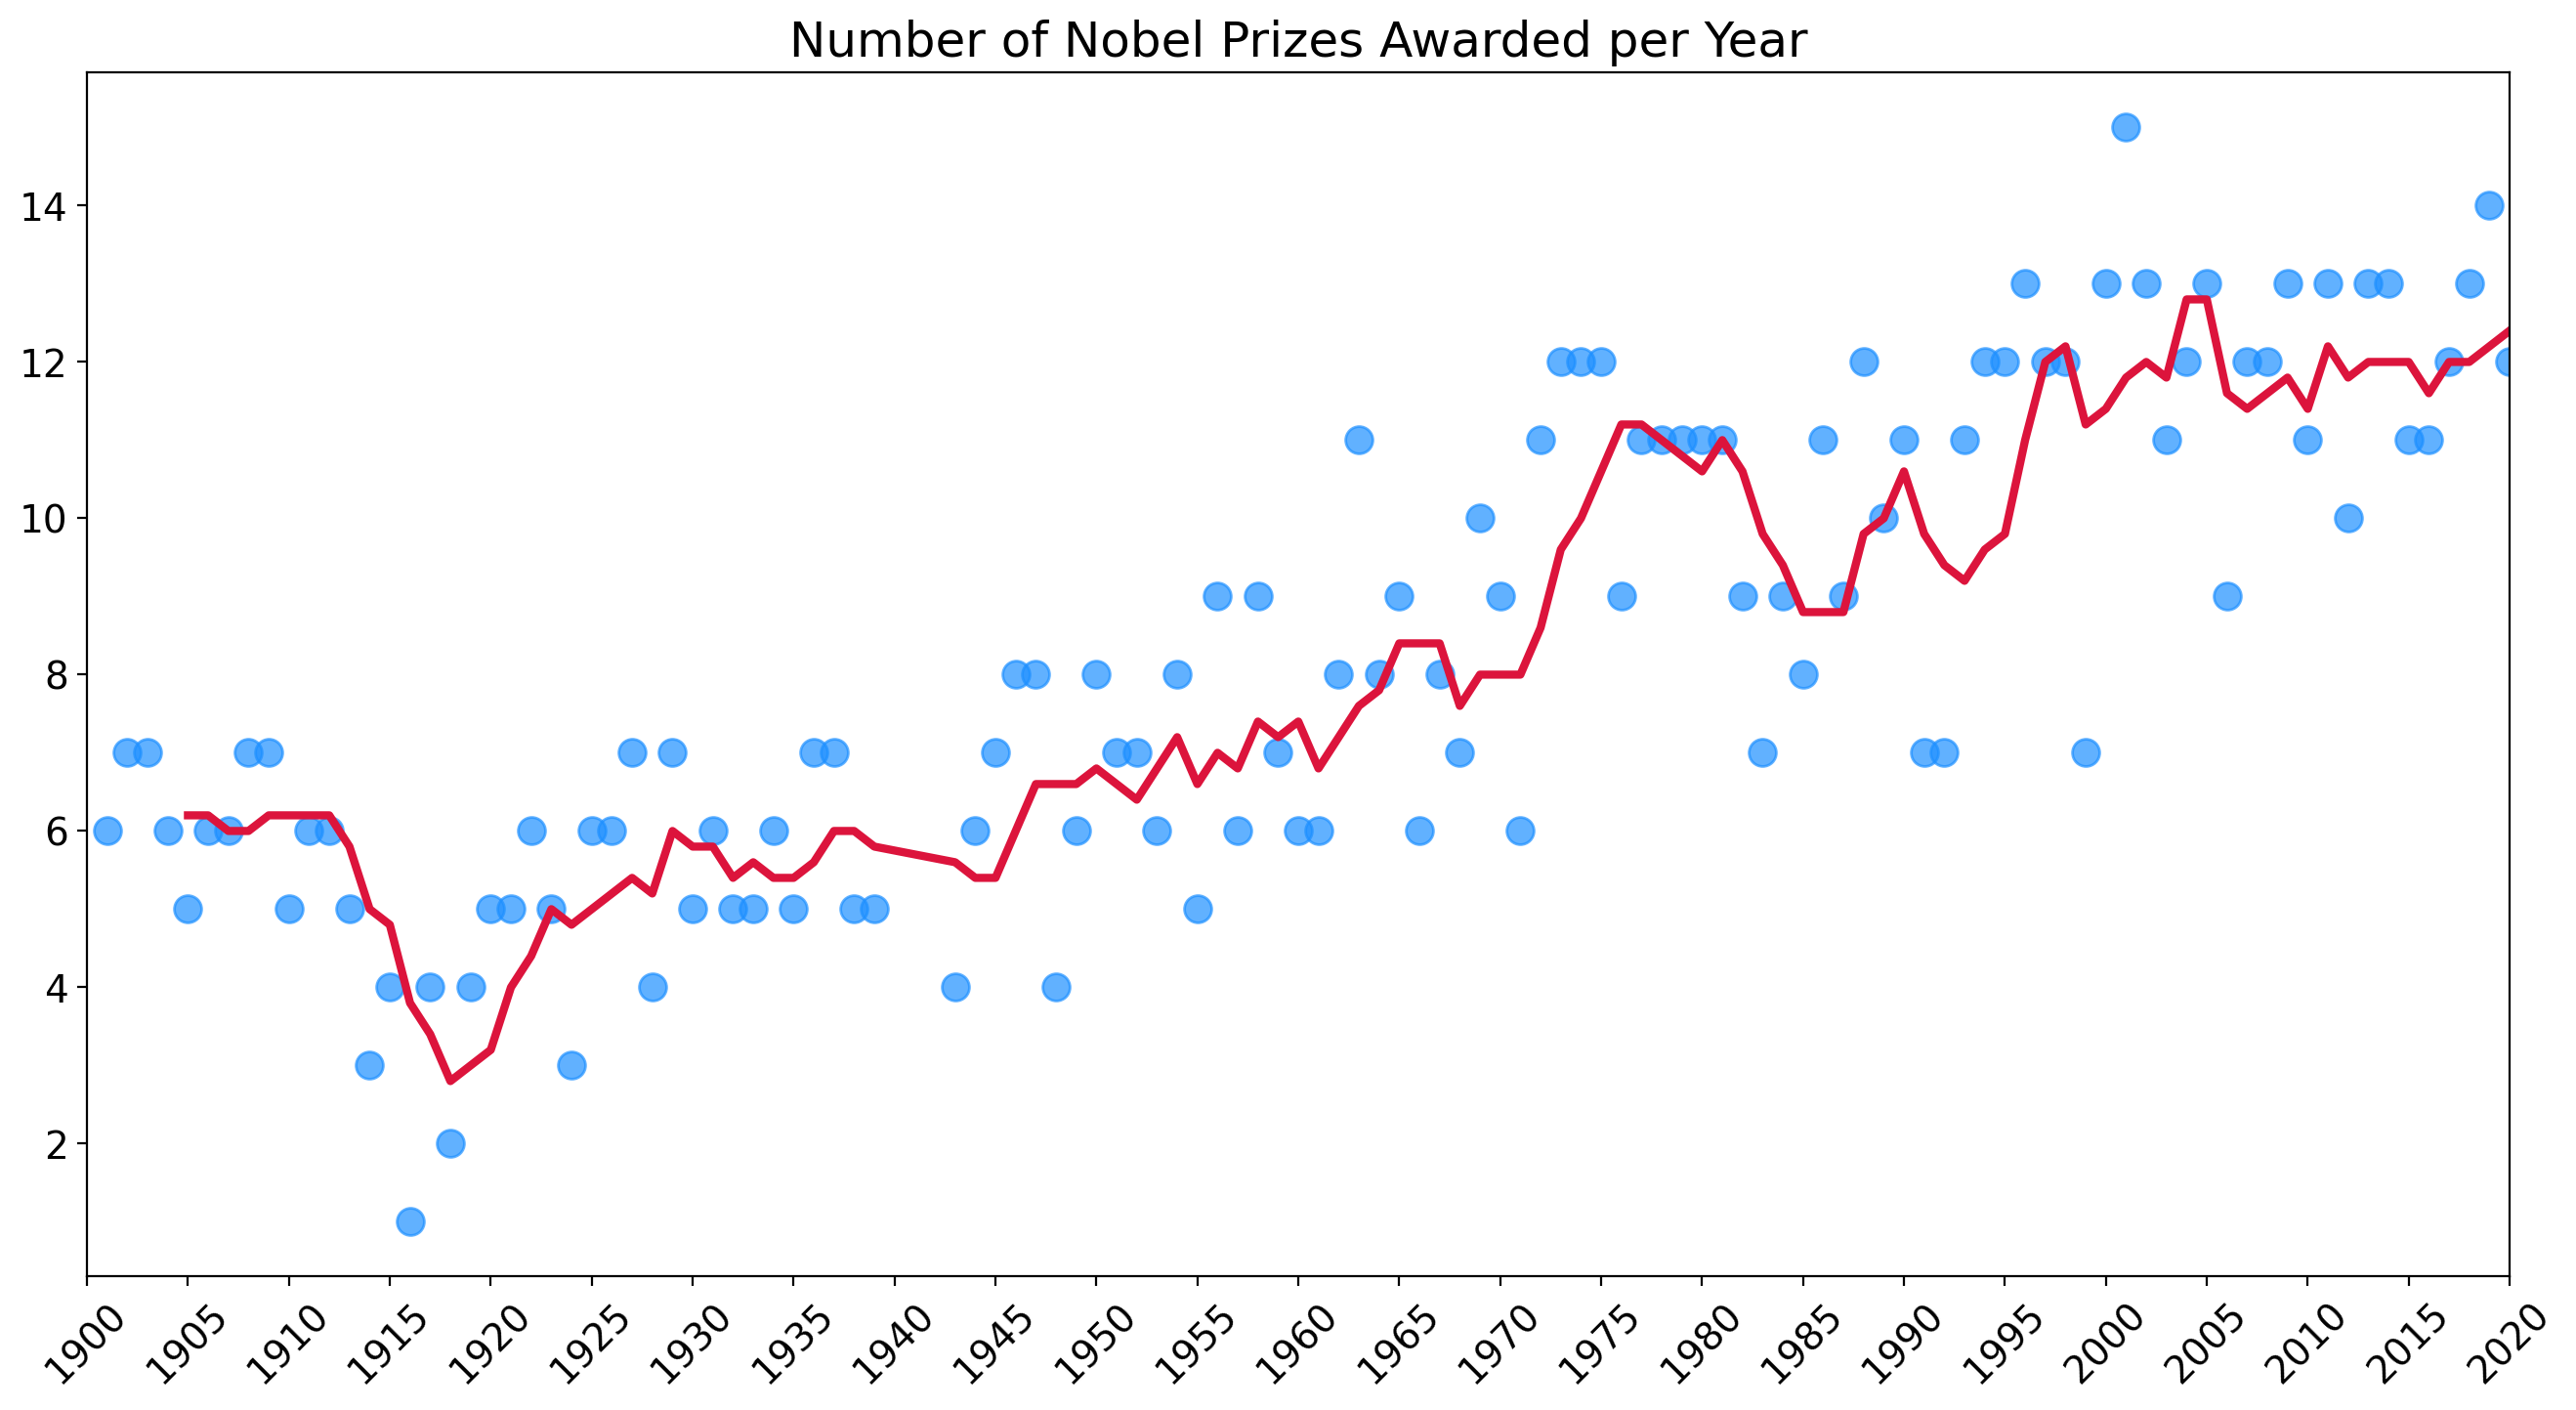

In [22]:
# Are more prizes awarded recently than when the prize was first created?
prize_per_year = df_data.groupby(by='year').count().prize
rolling_data = prize_per_year.rolling(window=5).mean()

plt.figure(figsize=(16, 8), dpi=200)
plt.title('Number of Nobel Prizes Awarded per Year', fontsize=18)
plt.yticks(fontsize=14)
plt.xticks(ticks=np.arange(1900, 2021, step=5),
           fontsize=14,
           rotation=45)

ax = plt.gca() # get current axis
ax.set_xlim(1900, 2020)

plt.scatter(x=prize_per_year.index,
           y=prize_per_year.values,
           c='dodgerblue',
           alpha=0.7,
           s=100,)

plt.plot(prize_per_year.index,
        rolling_data.values,
        c='crimson',
        linewidth=3,)

plt.show()


      share_pct
year           
1901   0.833333
1902   0.714286
1903   0.714286
1904   0.833333
1905   1.000000
...         ...
2016   0.545455
2017   0.500000
2018   0.461538
2019   0.428571
2020   0.500000

[117 rows x 1 columns]


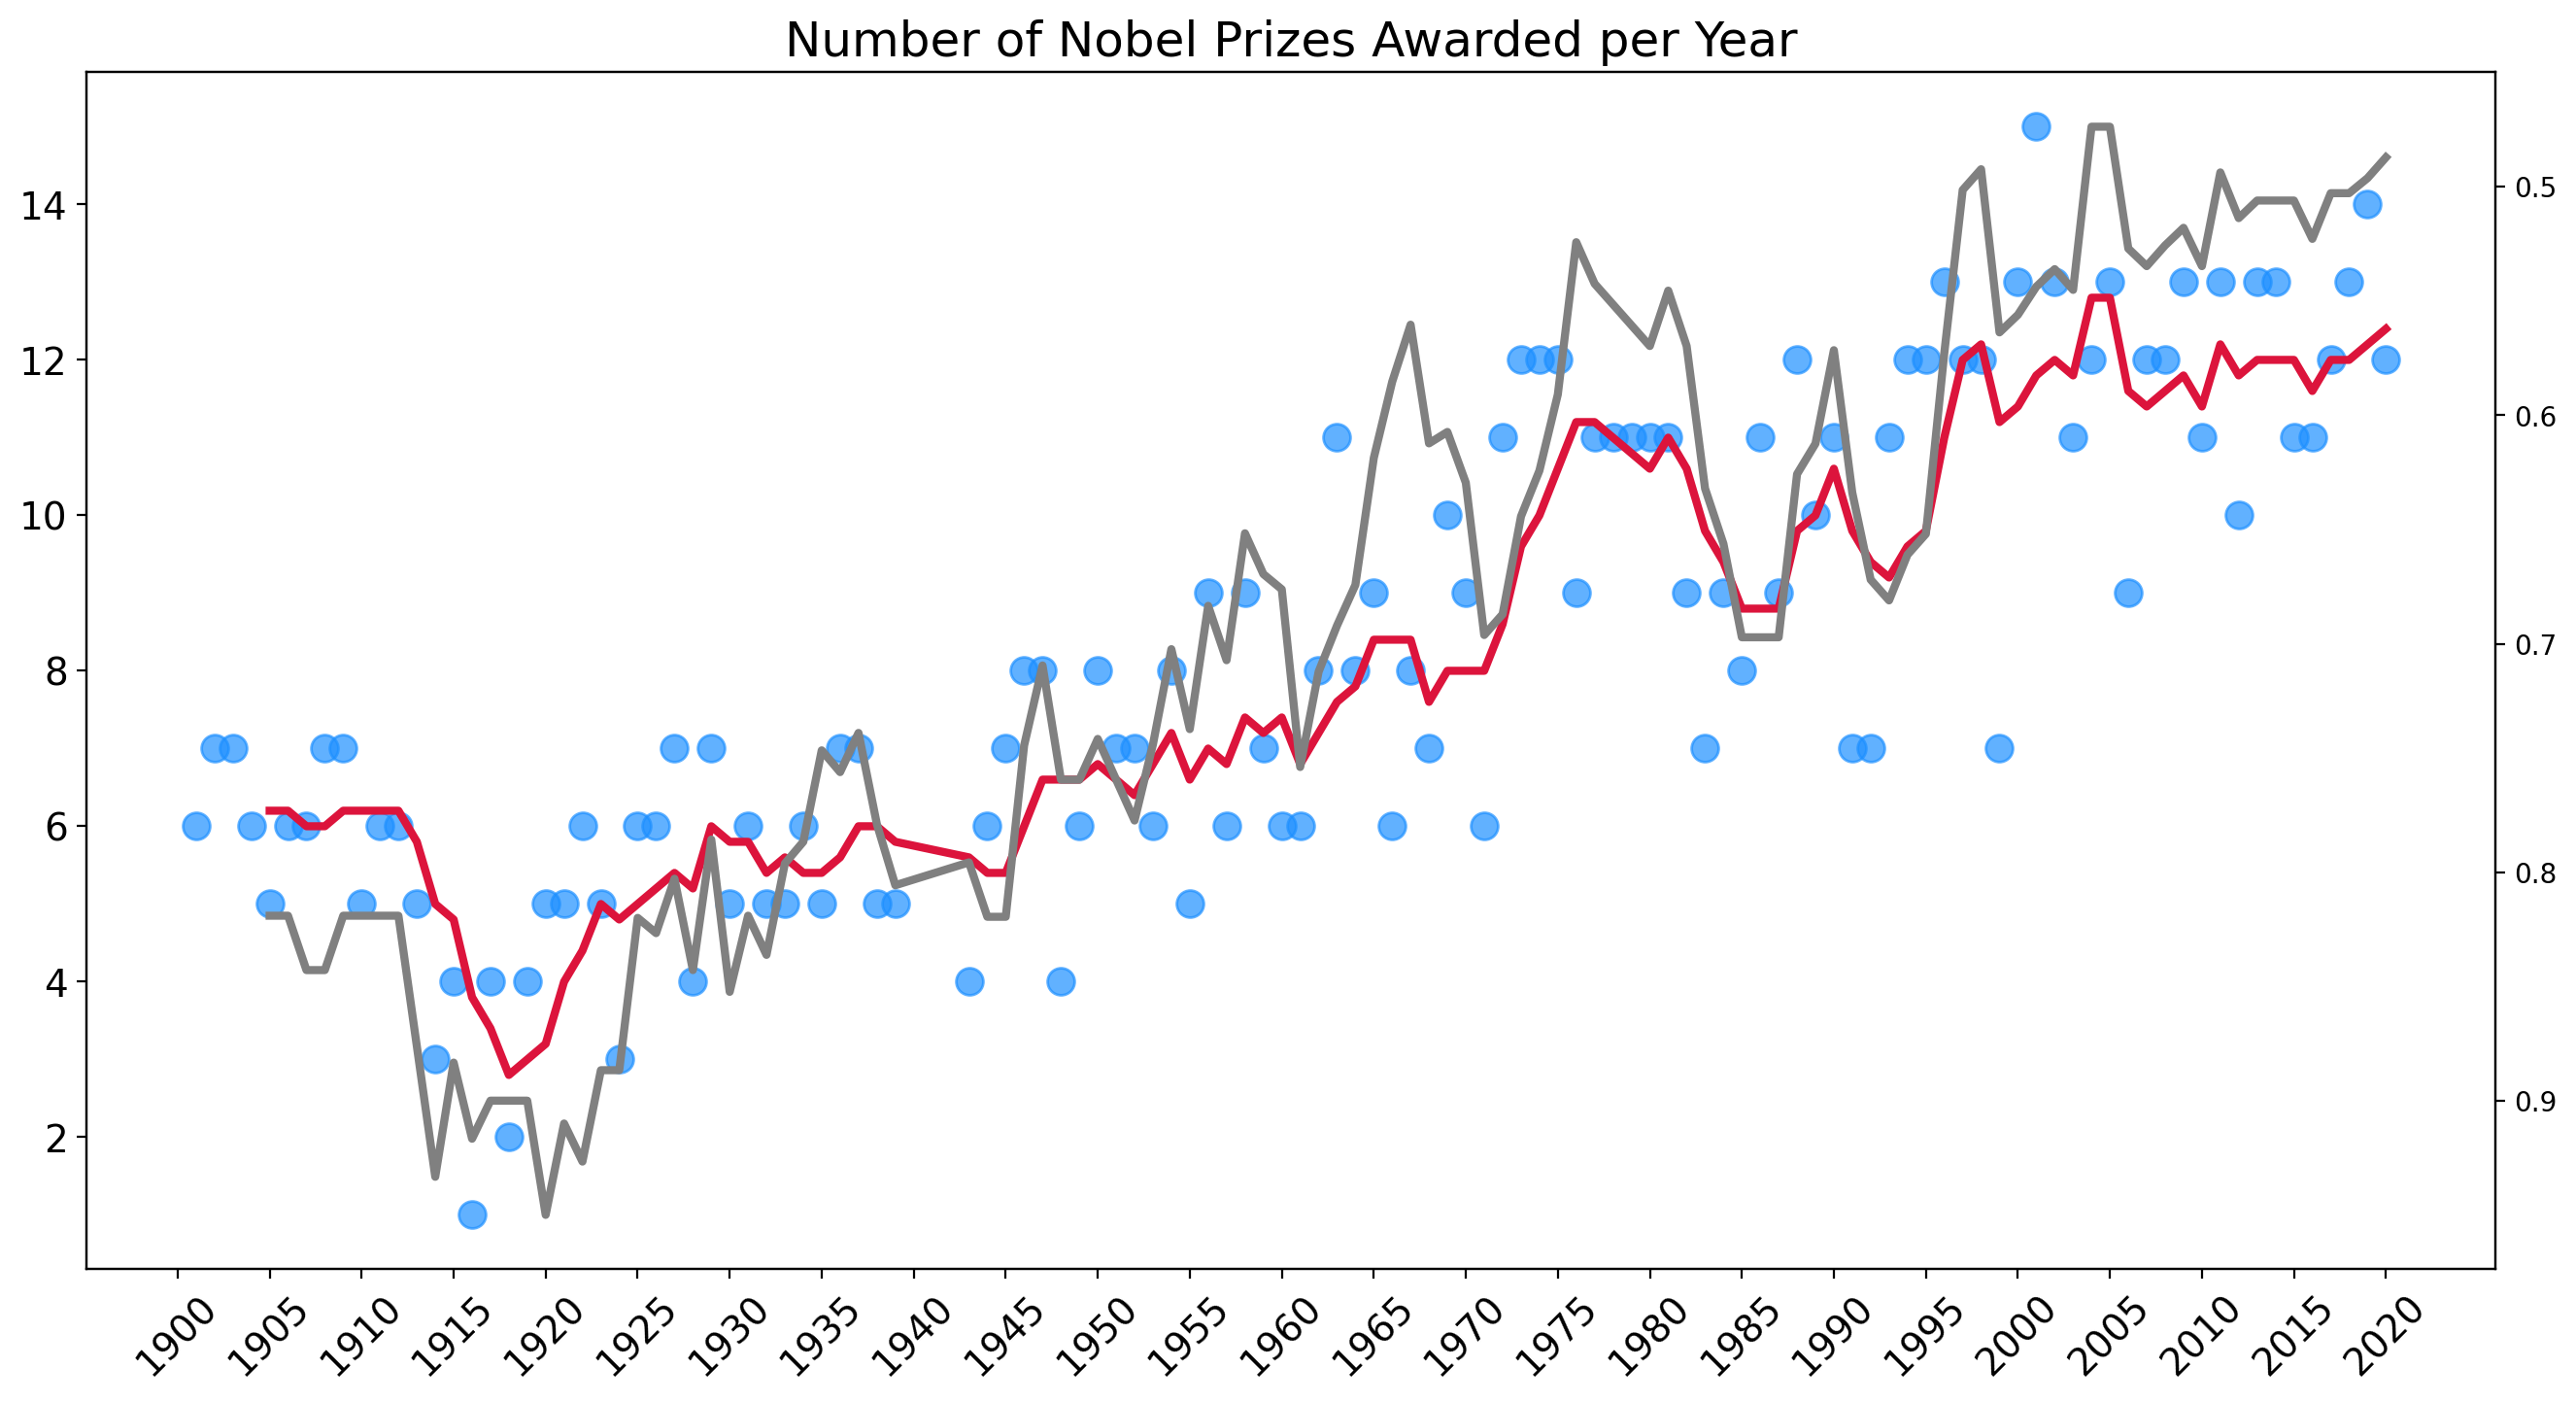

In [23]:
# Investigating if more prizes are shared than before.
yearly_avg_share = df_data.groupby('year').agg({'share_pct': pd.Series.mean})
print(yearly_avg_share)

share_moving_avg = yearly_avg_share.rolling(window=5).mean()

plt.figure(figsize=(16, 8), dpi=200)
plt.title('Number of Nobel Prizes Awarded per Year', fontsize=18)
plt.yticks(fontsize=14)
plt.xticks(ticks=np.arange(1900, 2021, step=5),
           fontsize=14,
           rotation=45)

ax1 = plt.gca()
ax2 = ax1.twinx() # create second y-axis
ax.set_xlim(1900, 2020)

# Can invert axis
ax2.invert_yaxis()

ax1.scatter(x=prize_per_year.index,
           y=prize_per_year.values,
           c='dodgerblue',
           alpha=0.7,
           s=100,)

ax1.plot(prize_per_year.index,
        rolling_data.values,
        c='crimson',
        linewidth=3,)

 # Adding prize share plot on second axis
ax2.plot(prize_per_year.index,
         share_moving_avg.values,
         c='grey',
         linewidth=3,
         )

plt.show()


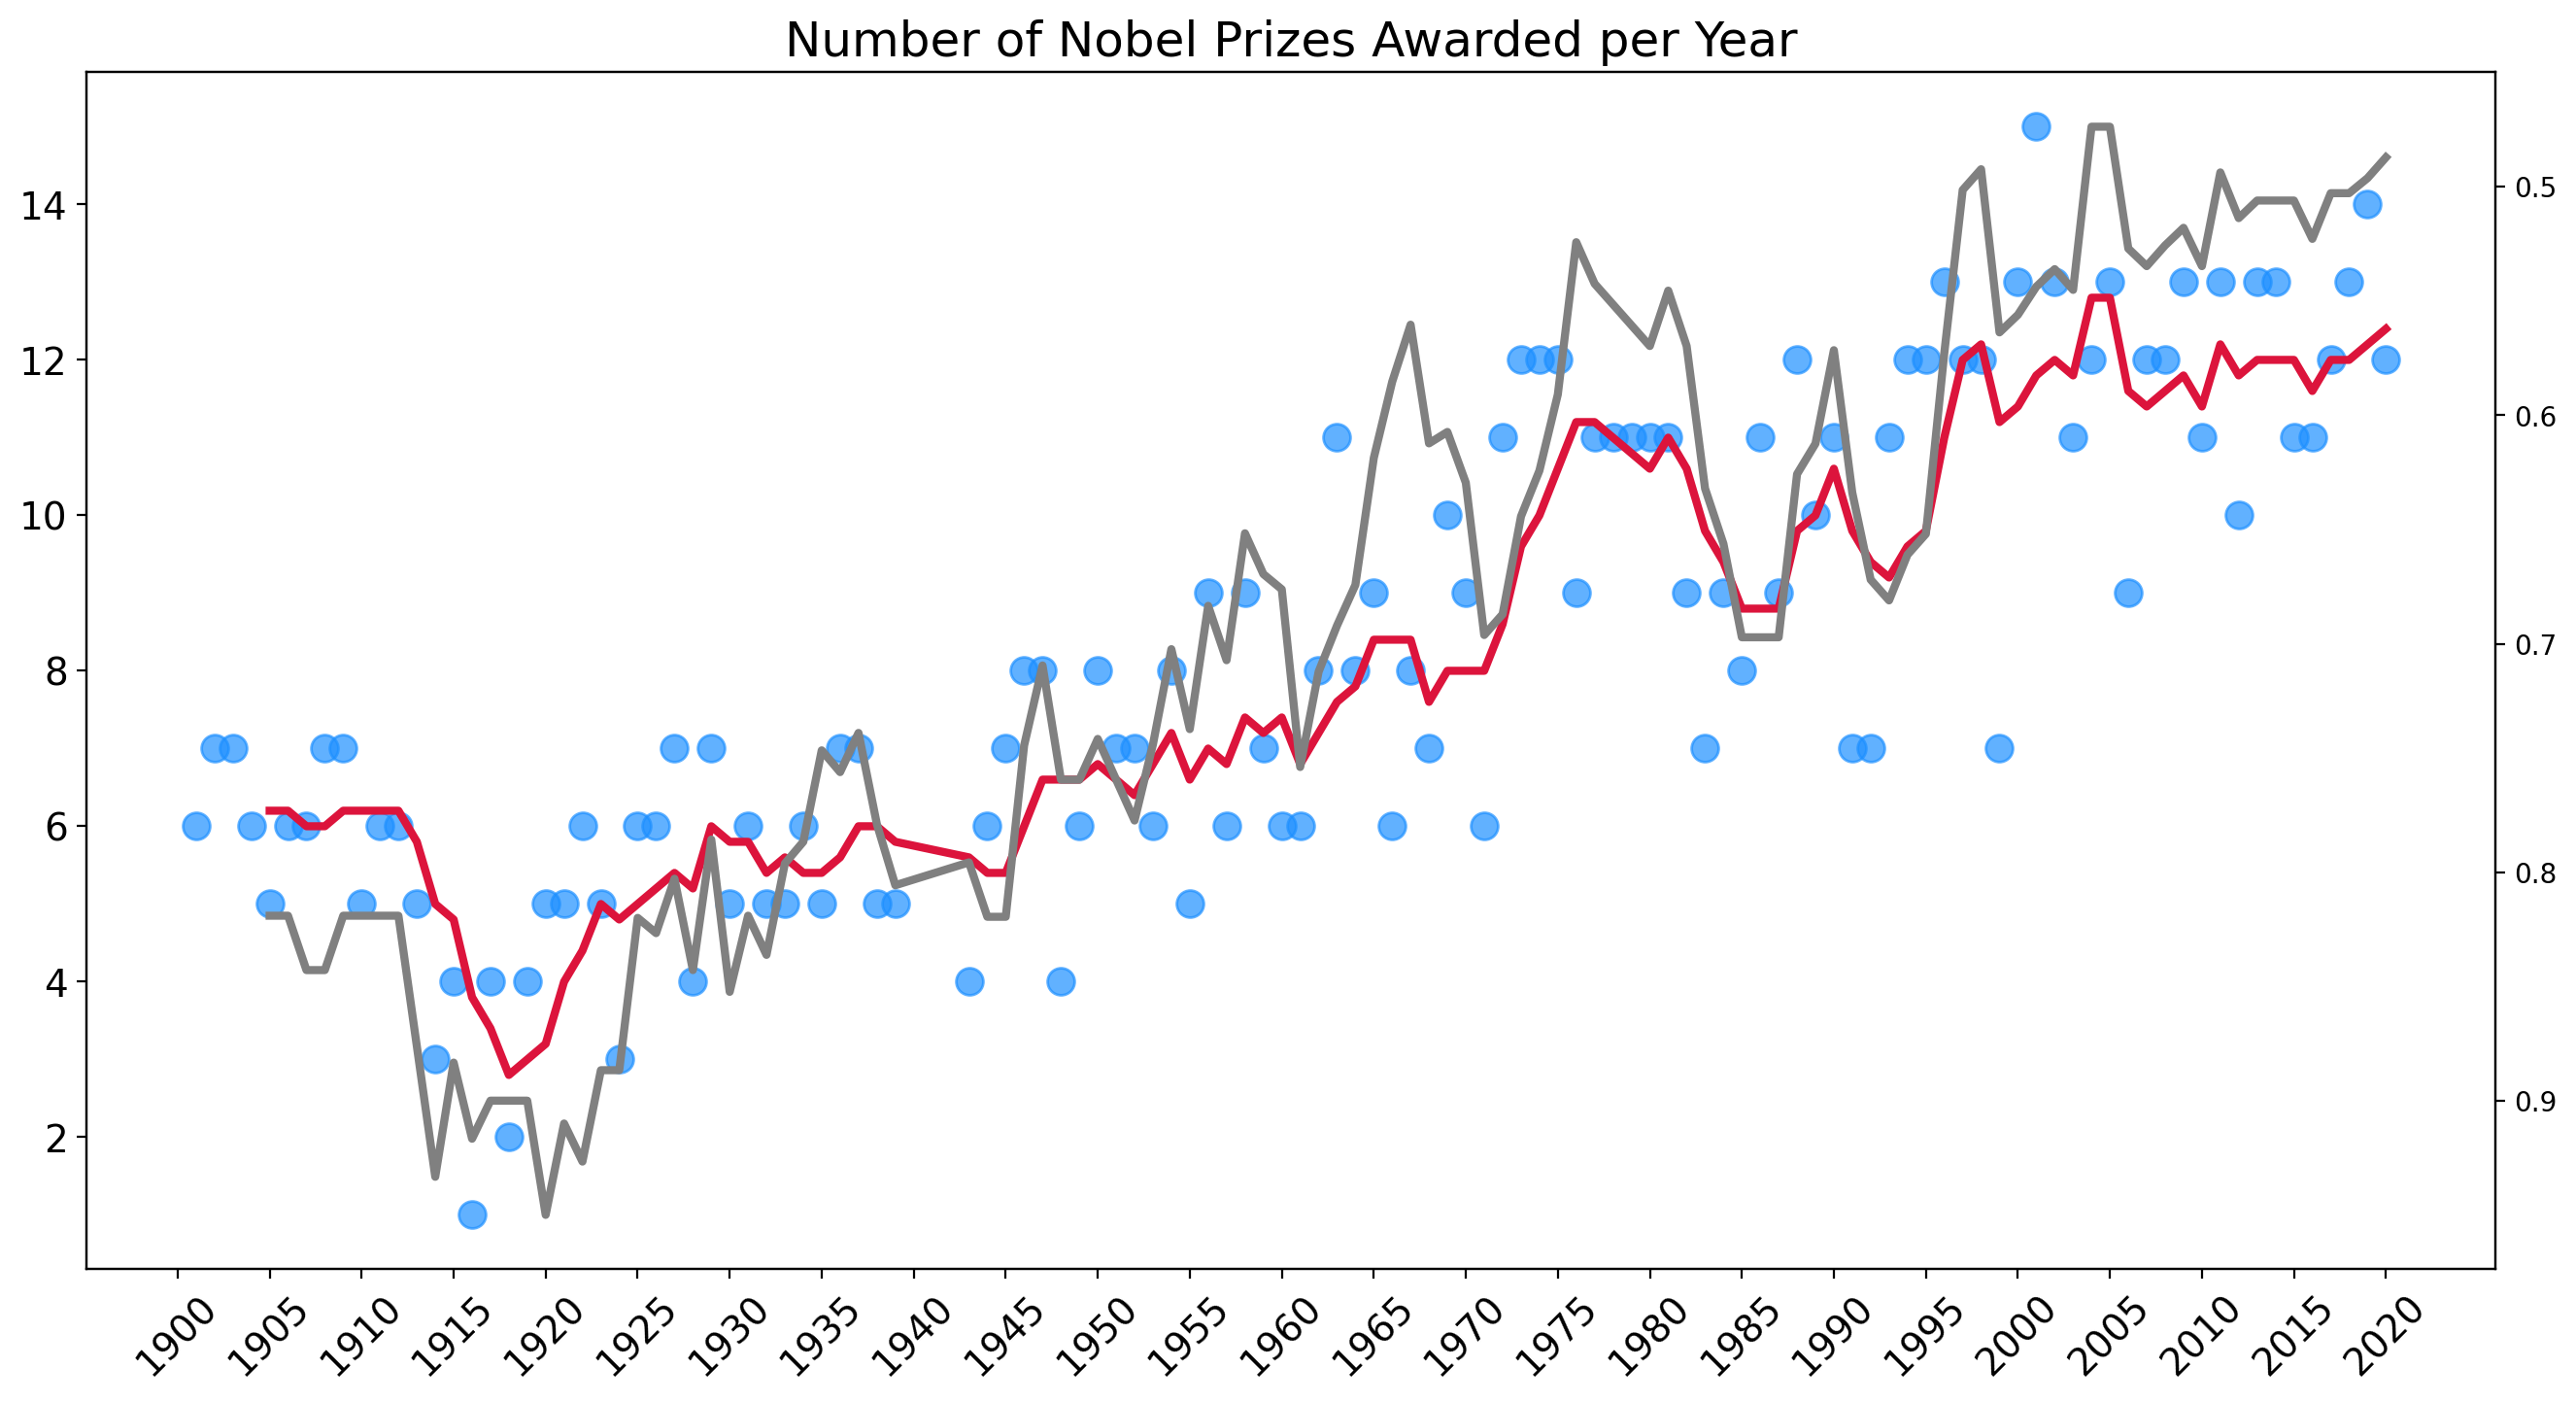

In [24]:
# How many Nobel Prizes are awarded per year?
plt.figure(figsize=(16, 8), dpi=200)
plt.title('Number of Nobel Prizes Awarded per Year', fontsize=18)
plt.yticks(fontsize=14)
plt.xticks(ticks=np.arange(1900, 2021, step=5),
           fontsize=14,
           rotation=45)

ax1 = plt.gca()
ax2 = ax1.twinx() # create second y-axis
ax.set_xlim(1900, 2020)

# Can invert axis
ax2.invert_yaxis()

ax1.scatter(x=prize_per_year.index,
           y=prize_per_year.values,
           c='dodgerblue',
           alpha=0.7,
           s=100,)

ax1.plot(prize_per_year.index,
        rolling_data.values,
        c='crimson',
        linewidth=3,)

 # Adding prize share plot on second axis
ax2.plot(prize_per_year.index,
         share_moving_avg.values,
         c='grey',
         linewidth=3,
         )

plt.show()

In [25]:
# Which countries actually get the most prizes?

# Top 20 Country Ranking
top_countries = df_data.groupby(['birth_country_current'], as_index=False).agg({'prize': pd.Series.count})
top_countries.sort_values('prize', inplace=True)
top20_countries = top_countries.tail(20)


h_bar = px.bar(x=top20_countries.prize,
               y=top20_countries.birth_country_current,
               orientation='h',
               color=top20_countries.prize,
               color_continuous_scale='Viridis',
               title='Top 20 Countries by Number of Prizes')

h_bar.update_layout(xaxis_title='Number of Prizes',
                    yaxis_title='Country',
                    #coloraxis_showscale=False  # you can remove the scale if you want, but I like it
                    )

h_bar.show()

In [26]:
# Choropleth Map
df_countries = df_data.groupby(['birth_country_current', 'ISO'], as_index=False).agg({'prize': pd.Series.count})
df_countries.sort_values('prize', ascending=False)

world_map = px.choropleth(df_countries,
                          locations='ISO',
                          color='prize',
                          hover_name='birth_country_current',
                          color_continuous_scale=px.colors.sequential.matter
                          )

world_map.update_layout(coloraxis_showscale=True,)

world_map.show()

In [27]:
# Was there anyone from Bulgaria who won the Nobel prize (up to 2020)?
# The answer is yes :).
df_data[df_data.birth_country_current == 'Bulgaria']

,year,category,prize,motivation,prize_share,laureate_type,full_name,birth_date,birth_city,birth_country,birth_country_current,sex,organization_name,organization_city,organization_country,ISO,share_pct
519,1981,Literature,The Nobel Prize in Literature 1981,"""for writings marked by a broad outlook, a wea...",1/1,Individual,Elias Canetti,1905-07-25,Ruse,Bulgaria,Bulgaria,Male,NaN,NaN,NaN,BGR,1.0


In [28]:
# Country Bar Chart with Prize Category
cat_country = df_data.groupby(['birth_country_current', 'category'],
                               as_index=False).agg({'prize': pd.Series.count})
cat_country.sort_values(by='prize', ascending=False, inplace=True)
print(cat_country)


        birth_country_current   category  prize
204  United States of America   Medicine     78
206  United States of America    Physics     70
201  United States of America  Chemistry     55
202  United States of America  Economics     49
198            United Kingdom   Medicine     28
..                        ...        ...    ...
190                    Turkey  Chemistry      1
207                 Venezuela   Medicine      1
208                   Vietnam      Peace      1
209                     Yemen      Peace      1
210                  Zimbabwe      Peace      1

[211 rows x 3 columns]


In [29]:
merged_df = pd.merge(cat_country, top20_countries, on='birth_country_current')

# changing column names
merged_df.columns = ['birth_country_current', 'category', 'cat_prize', 'total_prize']
merged_df.sort_values(by='total_prize', inplace=True)
print(merged_df)

        birth_country_current   category  cat_prize  total_prize
61               South Africa   Medicine          3            9
55                    Hungary  Chemistry          3            9
58               South Africa      Peace          3            9
81                    Hungary   Medicine          2            9
105                   Hungary  Economics          1            9
..                        ...        ...        ...          ...
3    United States of America  Economics         49          281
2    United States of America  Chemistry         55          281
9    United States of America      Peace         19          281
0    United States of America   Medicine         78          281
1    United States of America    Physics         70          281

[109 rows x 4 columns]


In [30]:
cat_country_bar = px.bar(x=merged_df.cat_prize,
               y=merged_df.birth_country_current,
               orientation='h',
               color=merged_df.category,
               color_continuous_scale='Viridis',
               title='Top 20 Countries by Number of Prizes and Category')

cat_country_bar.update_layout(xaxis_title='Number of Prizes',
                    yaxis_title='Country',
                    #coloraxis_showscale=False  # you can remove the scale if you want, but I like it
                    )

cat_country_bar.show()

In [31]:
# Prizes per country over time.
prize_by_year = df_data.groupby(['birth_country_current', 'year'], as_index=False).count()
prize_by_year = prize_by_year.sort_values('year')[['year', 'birth_country_current', 'prize']]
print(prize_by_year)

     year     birth_country_current  prize
312  1901               Netherlands      1
346  1901                    Poland      1
118  1901                    France      2
159  1901                   Germany      1
440  1901               Switzerland      1
..    ...                       ...    ...
244  2019                     India      1
221  2020                   Germany      1
158  2020                    France      1
533  2020            United Kingdom      2
622  2020  United States of America      7

[627 rows x 3 columns]


In [32]:
cumulative_prizes = prize_by_year.groupby(by=['birth_country_current',
                                              'year']).sum().groupby(level=[0]).cumsum()
cumulative_prizes.reset_index(inplace=True)
print(cumulative_prizes)

        birth_country_current  year  prize
0                     Algeria  1957      1
1                     Algeria  1997      2
2                   Argentina  1936      1
3                   Argentina  1947      2
4                   Argentina  1980      3
..                        ...   ...    ...
622  United States of America  2020    281
623                 Venezuela  1980      1
624                   Vietnam  1973      1
625                     Yemen  2011      1
626                  Zimbabwe  1960      1

[627 rows x 3 columns]


In [33]:
l_chart = px.line(cumulative_prizes,
                  x='year',
                  y='prize',
                  color='birth_country_current',
                  hover_name='birth_country_current')

l_chart.update_layout(xaxis_title='Year',
                      yaxis_title='Number of Prizes')

l_chart.show()

In [34]:
# The Top Research Organisations
top20_orgs = df_data.organization_name.value_counts()[:20]
top20_orgs.sort_values(ascending=True, inplace=True)
print(top20_orgs)

organization_name
Institut Pasteur                                 7
London University                                7
Harvard Medical School                           7
University College London                        7
Cornell University                               8
Bell Laboratories                                8
Yale University                                  9
MRC Laboratory of Molecular Biology             10
University of Oxford                            12
Max-Planck-Institut                             13
Rockefeller University                          13
Princeton University                            15
Columbia University                             17
California Institute of Technology (Caltech)    17
University of Cambridge                         18
University of Chicago                           20
Massachusetts Institute of Technology (MIT)     21
Stanford University                             23
Harvard University                              29
University of

In [35]:
org_bar = px.bar(x=top20_orgs.values,
                 y=top20_orgs.index,
                 orientation='h',
                 color=top20_orgs.values,
                 color_continuous_scale=px.colors.sequential.haline,
                 title='Top 20 Research Institutions by Number of'
                 )

org_bar.update_layout(xaxis_title='Number of Prizes',
                      yaxis_title='Country')

org_bar.show()

In [36]:
# Research Cities
top20_org_cities = df_data.organization_city.value_counts()[:20]
top20_org_cities.sort_values(ascending=True, inplace=True)
print(top20_org_cities)

organization_city
Zurich            8
Göttingen         8
New Haven, CT     9
Heidelberg        9
Boston, MA        9
Munich            9
Moscow           10
Stockholm        10
Oxford           12
Berlin           12
Pasadena, CA     17
Princeton, NJ    19
Chicago, IL      20
Berkeley, CA     21
Stanford, CA     24
Paris            25
London           27
Cambridge        31
New York, NY     45
Cambridge, MA    50
Name: count, dtype: int64


In [37]:
org_city_bar = px.bar(x=top20_org_cities.values,
                 y=top20_org_cities.index,
                 orientation='h',
                 color=top20_org_cities.values,
                 color_continuous_scale=px.colors.sequential.Plasma,
                 title='Which Cities Do the Most Research?'
                 )

org_city_bar.update_layout(xaxis_title='Number of Prizes',
                      yaxis_title='City')

org_city_bar.show()

In [38]:
# Laureate Birth Cities
top20_cities = df_data.birth_city.value_counts()[:20]
top20_cities.sort_values(ascending=True, inplace=True)
print(top20_cities)

birth_city
Uppsala                   3
Cairo                     4
Pittsburgh, PA            4
Montreal                  4
Frankfurt-on-the-Main     5
Prague                    5
Hamburg                   6
Stockholm                 6
Moscow                    7
Munich                    7
Budapest                  8
Brooklyn, NY              8
Boston, MA                8
Washington, DC            8
Berlin                   11
Chicago, IL              12
Vienna                   14
London                   19
Paris                    26
New York, NY             53
Name: count, dtype: int64


In [39]:
city_bar = px.bar(x=top20_cities.values,
                 y=top20_cities.index,
                 orientation='h',
                 color=top20_cities.values,
                 color_continuous_scale=px.colors.sequential.Viridis,
                 title='Where were the Nobel Laureates Born?'
                 )

city_bar.update_layout(xaxis_title='Number of Prizes',
                      yaxis_title='City')

city_bar.show()

In [40]:
# A Sunburst chart showing where discoveries take place.
country_city_org = df_data.groupby(by=['organization_country',
                                       'organization_city',
                                       'organization_name'], as_index=False).agg({'prize': pd.Series.count})

country_city_org = country_city_org.sort_values('prize', ascending=False)
print(country_city_org)

         organization_country            organization_city  \
205  United States of America                Cambridge, MA   
280  United States of America                 Stanford, CA   
206  United States of America                Cambridge, MA   
209  United States of America                  Chicago, IL   
195  United States of America                 Berkeley, CA   
..                        ...                          ...   
8                     Austria                    Innsbruck   
6                     Austria  Altenberg; Grünau im Almtal   
5                   Australia                 Weston Creek   
4                   Australia                     Nedlands   
1                   Argentina                 Buenos Aires   

                                     organization_name  prize  
205                                 Harvard University     29  
280                                Stanford University     23  
206        Massachusetts Institute of Technology (MIT)     21  

In [41]:
burst = px.sunburst(country_city_org,
                    path=['organization_country', 'organization_city', 'organization_name'],
                    values='prize',
                    title='Where do Discoveries Take Place?'
                    )

burst.update_layout(xaxis_title='Number of Prizes',
                    yaxis_title='City',)

burst.show()

In [42]:
# How old are the Nobel laureates at the time when they win the prize?
birth_years = df_data.birth_date.dt.year
df_data['winning_age'] = df_data.year - birth_years

In [43]:
df_data.head()

,year,category,prize,motivation,prize_share,laureate_type,full_name,birth_date,birth_city,birth_country,birth_country_current,sex,organization_name,organization_city,organization_country,ISO,share_pct,winning_age
0,1901,Chemistry,The Nobel Prize in Chemistry 1901,"""in recognition of the extraordinary services ...",1/1,Individual,Jacobus Henricus van 't Hoff,1852-08-30,Rotterdam,Netherlands,Netherlands,Male,Berlin University,Berlin,Germany,NLD,1.0,49.0
1,1901,Literature,The Nobel Prize in Literature 1901,"""in special recognition of his poetic composit...",1/1,Individual,Sully Prudhomme,1839-03-16,Paris,France,France,Male,NaN,NaN,NaN,FRA,1.0,62.0
2,1901,Medicine,The Nobel Prize in Physiology or Medicine 1901,"""for his work on serum therapy, especially its...",1/1,Individual,Emil Adolf von Behring,1854-03-15,Hansdorf (Lawice),Prussia (Poland),Poland,Male,Marburg University,Marburg,Germany,POL,1.0,47.0
3,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,Individual,Frédéric Passy,1822-05-20,Paris,France,France,Male,NaN,NaN,NaN,FRA,0.5,79.0
4,1901,Peace,The Nobel Peace Prize 1901,NaN,1/2,Individual,Jean Henry Dunant,1828-05-08,Geneva,Switzerland,Switzerland,Male,NaN,NaN,NaN,CHE,0.5,73.0


In [44]:
# Oldest and Youngest Winners
display(df_data.nlargest(n=1, columns='winning_age'))
display(df_data.nsmallest(n=2, columns='winning_age'))

,year,category,prize,motivation,prize_share,laureate_type,full_name,birth_date,birth_city,birth_country,birth_country_current,sex,organization_name,organization_city,organization_country,ISO,share_pct,winning_age
937,2019,Chemistry,The Nobel Prize in Chemistry 2019,“for the development of lithium-ion batteries”,1/3,Individual,John Goodenough,1922-07-25,Jena,Germany,Germany,Male,University of Texas,Austin TX,United States of America,DEU,0.333333,97.0


,year,category,prize,motivation,prize_share,laureate_type,full_name,birth_date,birth_city,birth_country,birth_country_current,sex,organization_name,organization_city,organization_country,ISO,share_pct,winning_age
885,2014,Peace,The Nobel Peace Prize 2014,"""for their struggle against the suppression of...",1/2,Individual,Malala Yousafzai,1997-07-12,Mingora,Pakistan,Pakistan,Female,NaN,NaN,NaN,PAK,0.5,17.0
85,1915,Physics,The Nobel Prize in Physics 1915,"""for their services in the analysis of crystal...",1/2,Individual,William Lawrence Bragg,1890-03-31,Adelaide,Australia,Australia,Male,Victoria University,Manchester,United Kingdom,AUS,0.5,25.0


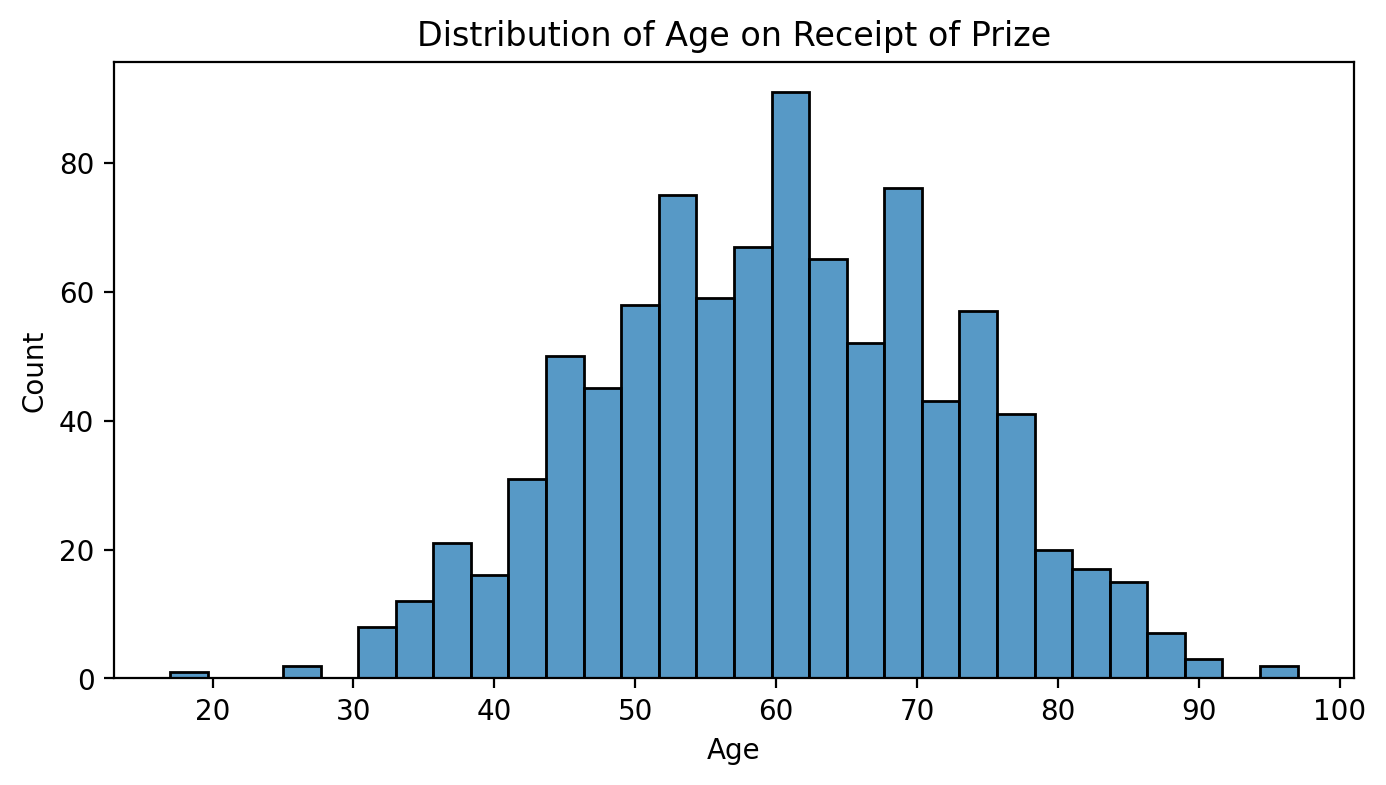

In [45]:
# Descriptive Statistics and Histogram
df_data.winning_age.describe()

plt.figure(figsize=(8, 4), dpi=200)

sns.histplot(data=df_data,
             x=df_data.winning_age,
             bins=30)

plt.xlabel('Age')
plt.title('Distribution of Age on Receipt of Prize')
plt.show()

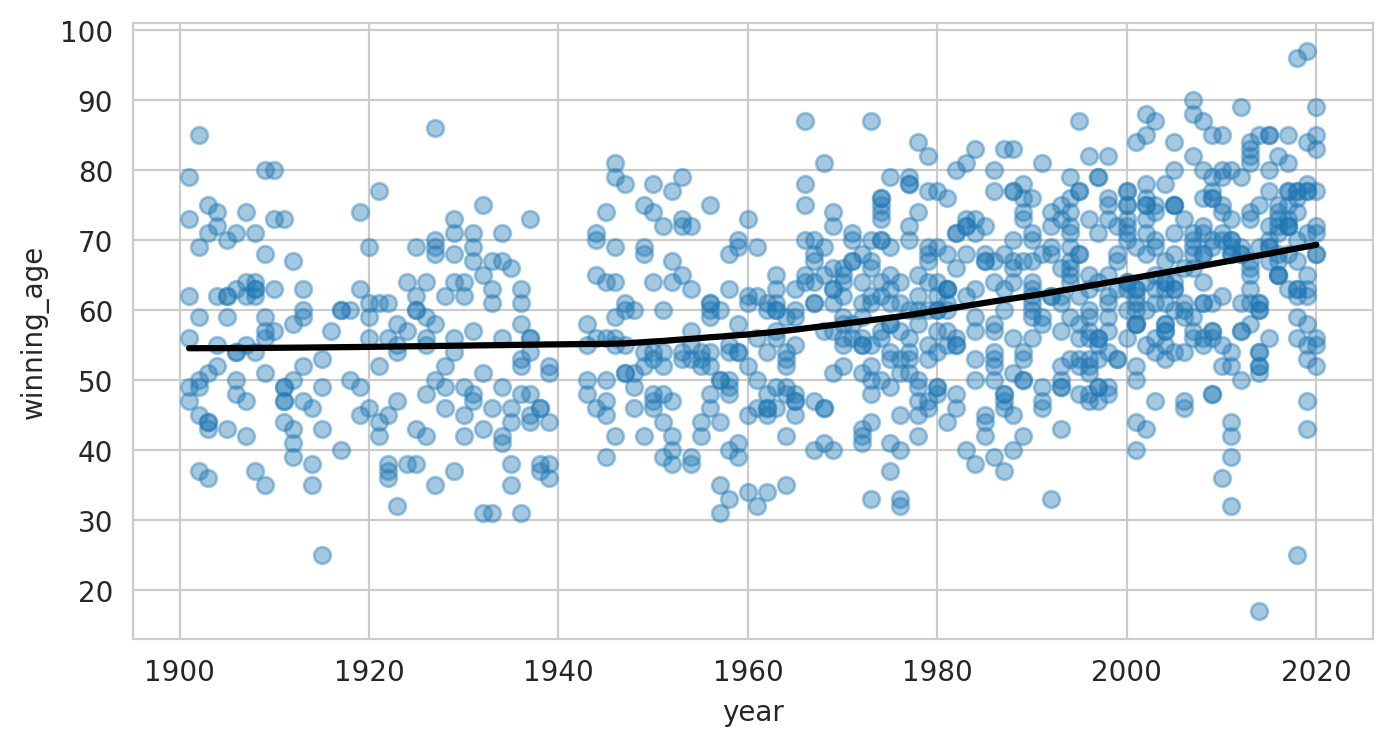

In [46]:
# Winning Age Over Time (All Categories)
plt.figure(figsize=(8, 4), dpi=200)
with sns.axes_style('whitegrid'):
  sns.regplot(data=df_data,
              x='year',
              y='winning_age',
              lowess=True,
              scatter_kws = {'alpha': 0.4},
                line_kws={'color': 'black'})

  plt.show()

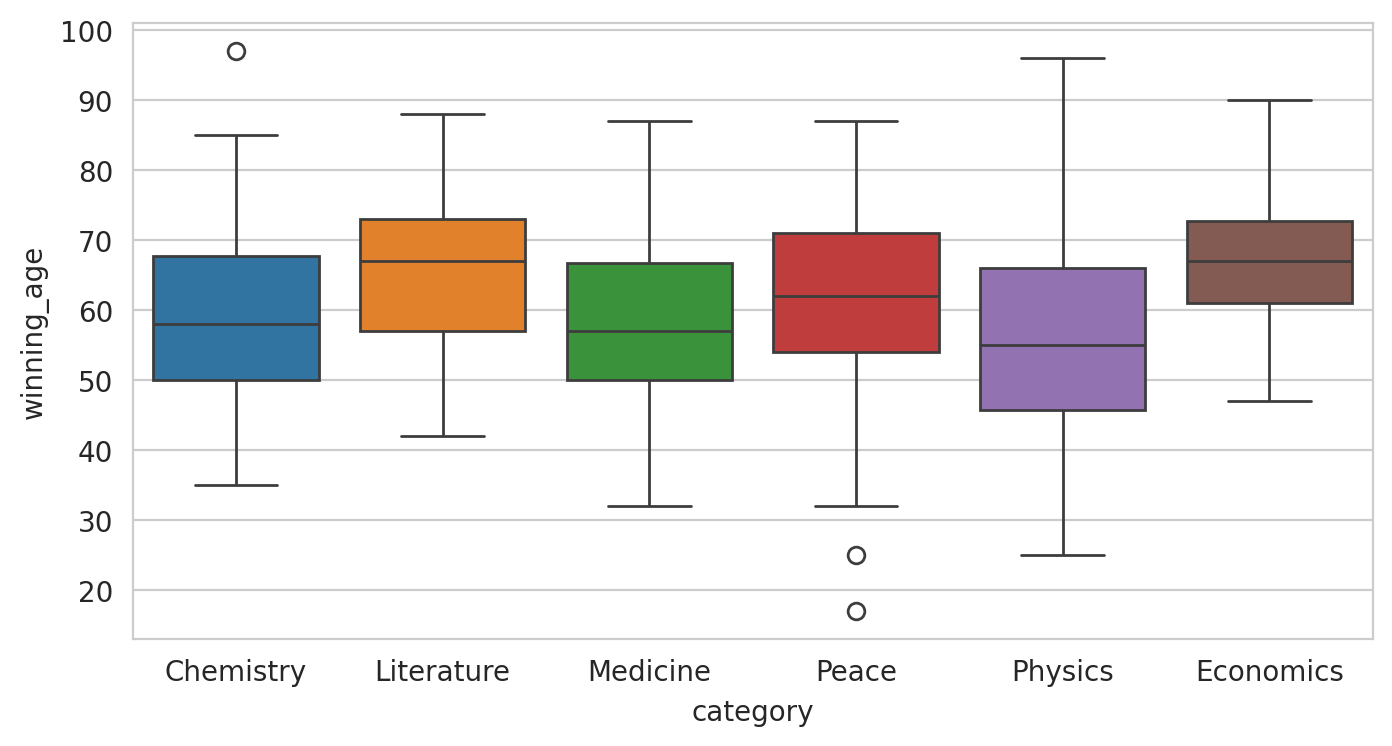

In [47]:
# Age Differences between Categories
plt.figure(figsize=(8,4), dpi=200)
with sns.axes_style('whitegrid'):
  sns.boxplot(data=df_data,
              x='category',
              y='winning_age',
              hue="category",
              )

plt.show()

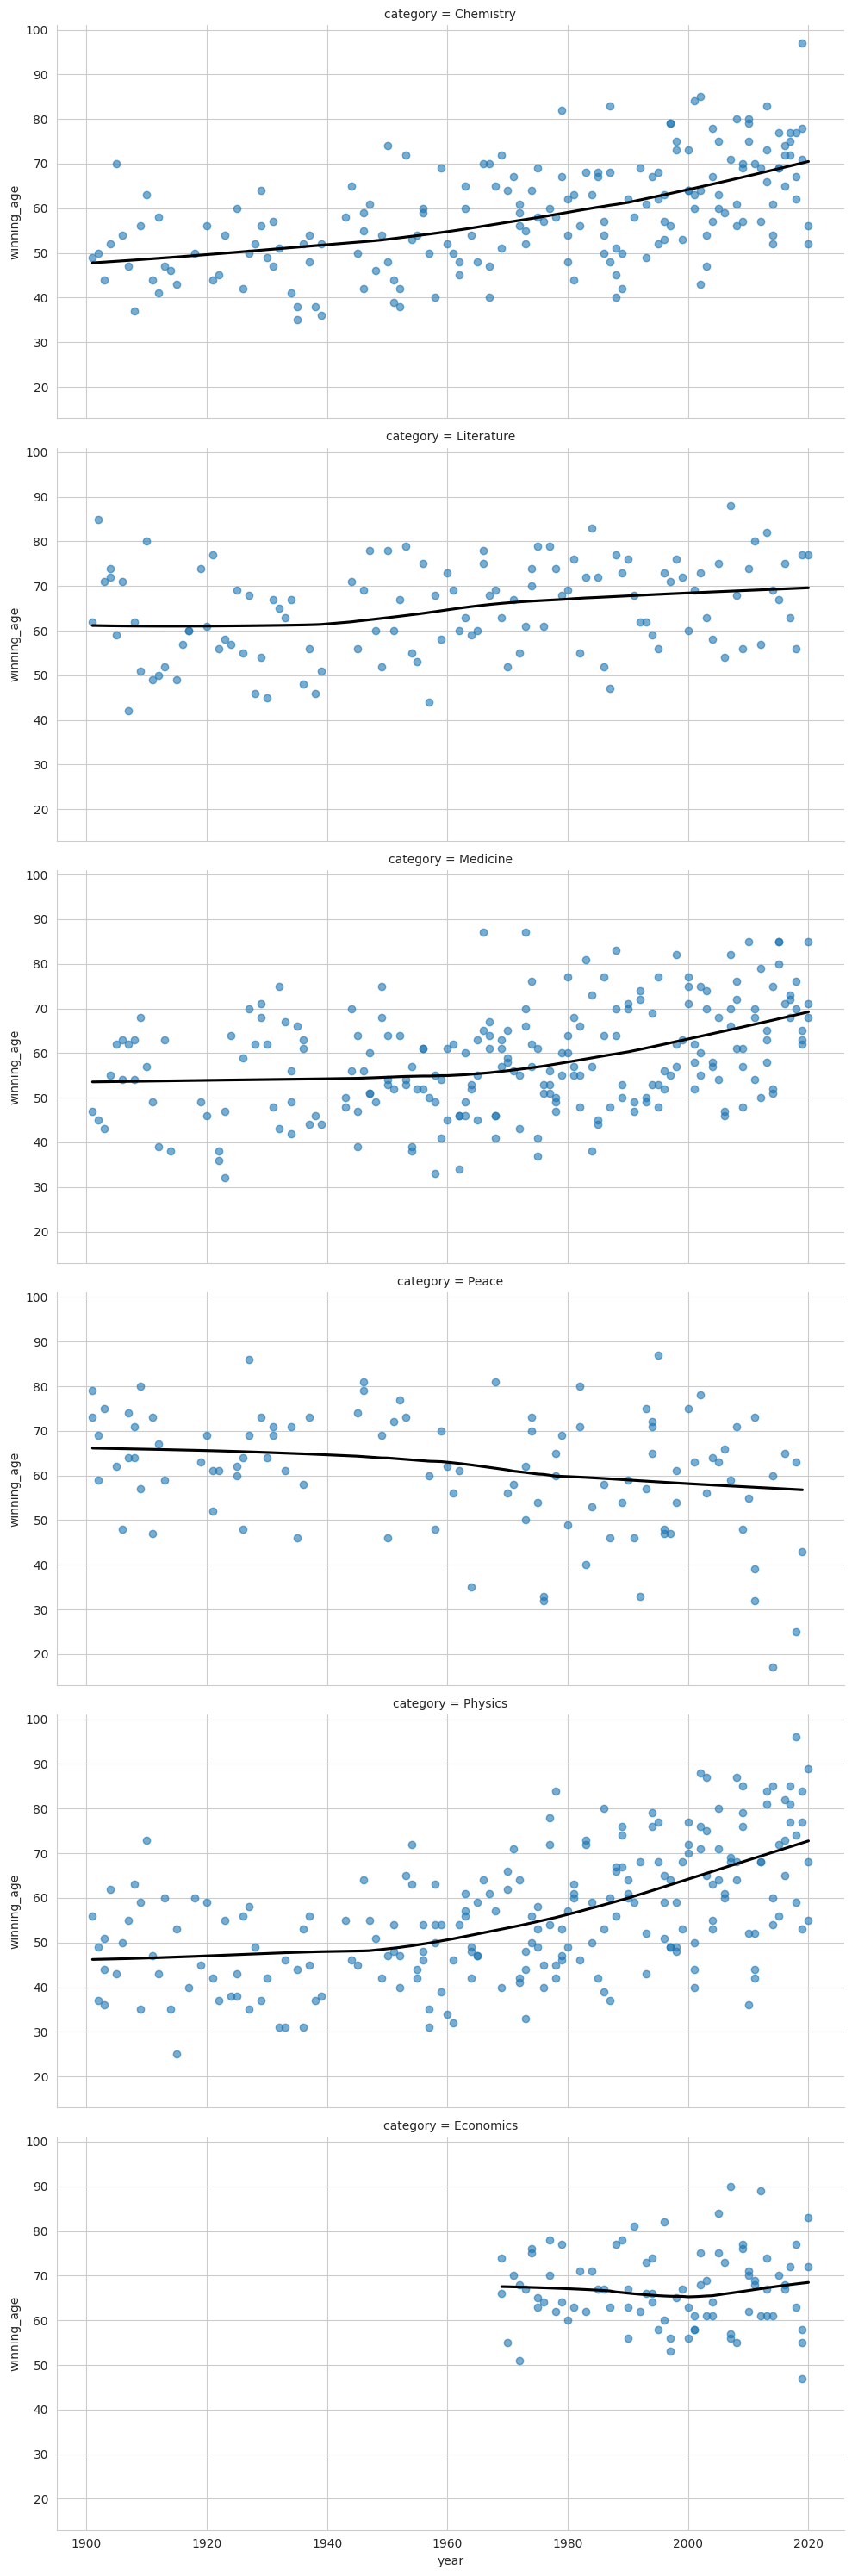

In [48]:
# Laureate Age over Time by Category
with sns.axes_style('whitegrid'):
    sns.lmplot(data=df_data,
               x='year',
               y='winning_age',
               row = 'category',
               lowess=True,
               aspect=2,
               scatter_kws = {'alpha': 0.6},
               line_kws = {'color': 'black'},)

plt.show()

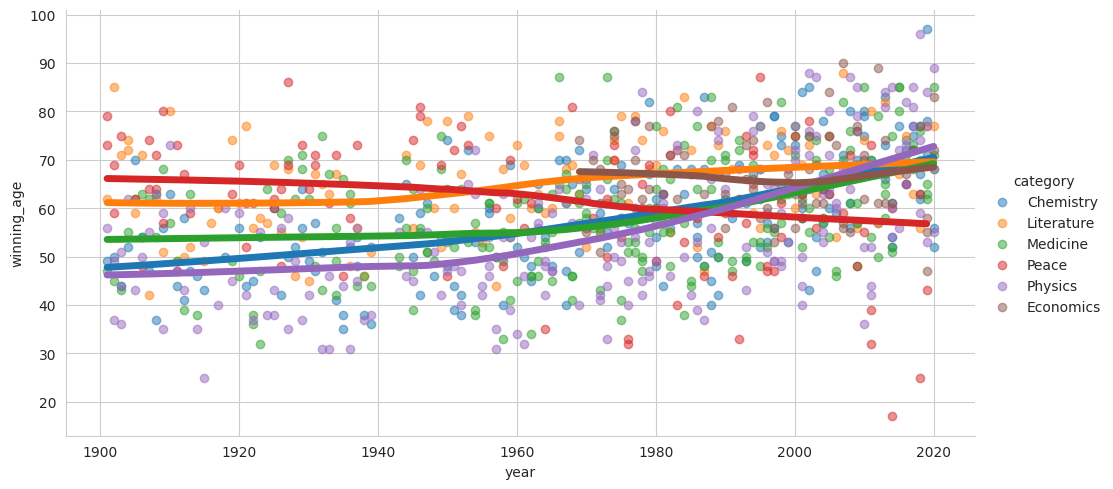

In [49]:
with sns.axes_style("whitegrid"):
    sns.lmplot(data=df_data,
               x='year',
               y='winning_age',
               hue='category', # we used this to combine them (instead of row)
               lowess=True,
               aspect=2,
               scatter_kws={'alpha': 0.5},
               line_kws={'linewidth': 5})

plt.show()